# ESOL QSPR：RDKit 特征与随机森林

保留现有特征、模型参数及评估协议。每次从当前目录读取数据，独立运行。

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdkit import Chem

# 从项目根目录或 notebooks 目录启动都能找到数据，不依赖本机绝对路径。
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "delaney-processed.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("请从项目根目录或 notebooks 目录启动。")
data_path = project_root / "data" / "delaney-processed.csv"
df = pd.read_csv(data_path)
target = "measured log solubility in mols per litre"
required = ["Compound ID", "smiles", target]
if not set(required).issubset(df.columns) or df[required].isna().any().any():
    raise ValueError("必要列缺失或含缺失值；停止运行，不自动删除数据。")
if not np.isfinite(df[target].to_numpy(dtype=float)).all():
    raise ValueError("目标值包含非有限数值。")
molecules = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
invalid_rows = [i for i, mol in enumerate(molecules)
                if mol is None or mol.GetNumAtoms() == 0]
if invalid_rows:
    raise ValueError(f"无法构建分子的行号：{invalid_rows}")
canonical_smiles = [Chem.MolToSmiles(mol) for mol in molecules]
print("Data shape:", df.shape)
print("SHA256:", hashlib.sha256(data_path.read_bytes()).hexdigest())
print("Duplicate rows:", int(df.duplicated().sum()))
print("Repeated canonical structures:", int(pd.Series(canonical_smiles).duplicated().sum()))
# 重复结构仅报告，保留原始行顺序和既有数据划分。
from rdkit.Chem import Descriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Data shape: (1128, 10)
SHA256: 3fa1b501b2f940d4b016c3798f5fcd4c897b8455a0217efbb3715ac35011f290
Duplicate rows: 0
Repeated canonical structures: 11


## 特征构建

5 个 RDKit 描述符：分子量、logP、TPSA、氢键供体数、氢键受体数；Morgan 指纹 radius=2、2048 位；拼接后 2053 维。

In [2]:
from rdkit import Chem
from rdkit.Chem import Descriptors

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return {
            "MW_rdkit": None,
            "logP_rdkit": None,
            "TPSA_rdkit": None,
            "HBD_rdkit": None,
            "HBA_rdkit": None
        }

    return {
        "MW_rdkit": Descriptors.MolWt(mol),
        "logP_rdkit": Descriptors.MolLogP(mol),
        "TPSA_rdkit": Descriptors.TPSA(mol),
        "HBD_rdkit": Descriptors.NumHDonors(mol),
        "HBA_rdkit": Descriptors.NumHAcceptors(mol)
    }
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import numpy as np

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    fp = morgan_generator.GetFingerprint(mol)

    return np.array(fp)

In [3]:
descriptor_df = df["smiles"].apply(calculate_descriptors).apply(pd.Series)
df_rdkit = pd.concat([df, descriptor_df], axis=1)
features = ["MW_rdkit", "logP_rdkit", "TPSA_rdkit", "HBD_rdkit", "HBA_rdkit"]
X = descriptor_df[features]
y = df[target]
fingerprints = np.array([smiles_to_fingerprint(smiles) for smiles in df["smiles"]])
X_combined = np.hstack([X.to_numpy(), fingerprints])
y_fp = y.to_numpy()
if not np.isfinite(X_combined).all():
    raise ValueError("特征包含缺失或非有限数值；停止，不自动删除数据。")
print("Descriptors:", X.shape, "Morgan:", fingerprints.shape, "Combined:", X_combined.shape)

Descriptors: (1128, 5) Morgan: (1128, 2048) Combined: (1128, 2053)


## 固定数据划分

随机划分 80/20，seed=42。骨架划分沿用按组大小降序的贪心分配；所有无环分子仍属于同一空骨架组。两种测试集不同，成绩不可混为同一基准。

In [4]:
indices = np.arange(len(df))
random_train_idx, random_test_idx = train_test_split(indices, test_size=0.2, random_state=42)
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )

df_rdkit["scaffold"] = df_rdkit["smiles"].apply(
    get_scaffold
)
scaffold_groups = {}

for idx, scaffold in enumerate(
    df_rdkit["scaffold"]
):
    scaffold_groups.setdefault(
        scaffold,
        []
    ).append(idx)
scaffold_sets = sorted(
    scaffold_groups.values(),
    key=len,
    reverse=True
)
train_indices = []
test_indices = []

train_cutoff = int(
    0.8 * len(df_rdkit)
)

for group in scaffold_sets:

    if len(train_indices) + len(group) <= train_cutoff:
        train_indices.extend(group)

    else:
        test_indices.extend(group)
scaffold_train_idx = np.asarray(train_indices)
scaffold_test_idx = np.asarray(test_indices)
for train_part, test_part in [(random_train_idx, random_test_idx),
                              (scaffold_train_idx, scaffold_test_idx)]:
    assert set(train_part).isdisjoint(test_part)
    assert sorted(np.concatenate([train_part, test_part]).tolist()) == indices.tolist()
assert set(df_rdkit.loc[train_indices, "scaffold"]).isdisjoint(
    df_rdkit.loc[test_indices, "scaffold"])
print("Random train/test:", len(random_train_idx), len(random_test_idx))
print("Scaffold train/test:", len(train_indices), len(test_indices))
print("Empty scaffold molecules:", int((df_rdkit["scaffold"] == "").sum()))
overlap = set(np.asarray(canonical_smiles)[random_train_idx]) & set(np.asarray(canonical_smiles)[random_test_idx])
print("Canonical structures shared by random train/test:", len(overlap))

Random train/test: 902 226
Scaffold train/test: 902 226
Empty scaffold molecules: 317
Canonical structures shared by random train/test: 4


## 训练与测试评估

误差在原始 logS 标度计算。所有模型、特征与划分均来自既有实验。

In [5]:
feature_sets = {
    "RF_descriptors": X.to_numpy(),
    "RF_morgan": fingerprints,
    "RF_combined": X_combined,
}
split_sets = {
    "random_80_20": (random_train_idx, random_test_idx),
    "murcko_scaffold_80_20": (scaffold_train_idx, scaffold_test_idx),
}
rows = []
trained_models = {}
predictions = {}
for split_name, (train_part, test_part) in split_sets.items():
    for model_name, feature_values in feature_sets.items():
        # 保留原模型的 300 棵树和随机种子，不搜索新参数。
        model = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
        model.fit(feature_values[train_part], y_fp[train_part])
        prediction = model.predict(feature_values[test_part])
        trained_models[(split_name, model_name)] = model
        predictions[(split_name, model_name)] = prediction
        rows.append({
            "family": "QSPR", "model": model_name, "split": split_name, "seed": 42,
            "n_train": len(train_part), "n_validation": 0, "n_test": len(test_part),
            "best_epoch": None,
            "MAE": mean_absolute_error(y_fp[test_part], prediction),
            "RMSE": mean_squared_error(y_fp[test_part], prediction) ** 0.5,
            "R2": r2_score(y_fp[test_part], prediction),
        })
# 保留原有线性基线，只在原有随机划分上评估。
linear_model = LinearRegression().fit(X.to_numpy()[random_train_idx], y_fp[random_train_idx])
linear_prediction = linear_model.predict(X.to_numpy()[random_test_idx])
rows.append({
    "family": "QSPR", "model": "Linear_descriptors", "split": "random_80_20", "seed": 42,
    "n_train": len(random_train_idx), "n_validation": 0, "n_test": len(random_test_idx),
    "best_epoch": None,
    "MAE": mean_absolute_error(y_fp[random_test_idx], linear_prediction),
    "RMSE": mean_squared_error(y_fp[random_test_idx], linear_prediction) ** 0.5,
    "R2": r2_score(y_fp[random_test_idx], linear_prediction),
})
current_results = pd.DataFrame(rows)
family = "QSPR"

In [6]:
# 重跑只更新本方法的结果，保留另一份笔记已生成的结果。
result_path = project_root / "results" / "model_comparison.csv"
result_path.parent.mkdir(exist_ok=True)
columns = ["family", "model", "split", "seed", "n_train", "n_validation",
           "n_test", "best_epoch", "MAE", "RMSE", "R2"]
current_results = current_results.reindex(columns=columns)
if result_path.exists():
    previous_results = pd.read_csv(result_path)
    if list(previous_results.columns) != columns:
        raise ValueError("结果表格式不同，请先保存原表再运行。")
    final_results = pd.concat([
        previous_results.loc[previous_results["family"] != family], current_results
    ], ignore_index=True)
else:
    final_results = current_results
final_results = final_results.sort_values(["family", "split", "model", "seed"])
final_results.to_csv(result_path, index=False, float_format="%.10f")
display(current_results)
print("Saved:", result_path.relative_to(project_root))

,family,model,split,seed,n_train,n_validation,n_test,best_epoch,MAE,RMSE,R2
0,QSPR,RF_descriptors,random_80_20,42,902,0,226,None,0.586278,0.842755,0.849743
1,QSPR,RF_morgan,random_80_20,42,902,0,226,None,0.875498,1.161034,0.714818
2,QSPR,RF_combined,random_80_20,42,902,0,226,None,0.549048,0.795861,0.866000
3,QSPR,RF_descriptors,murcko_scaffold_80_20,42,902,0,226,None,0.777257,1.033844,0.742246
4,QSPR,RF_morgan,murcko_scaffold_80_20,42,902,0,226,None,1.290942,1.680499,0.318962
5,QSPR,RF_combined,murcko_scaffold_80_20,42,902,0,226,None,0.706090,0.951204,0.781807
6,QSPR,Linear_descriptors,random_80_20,42,902,0,226,None,0.837695,1.105159,0.741606


Saved: results\model_comparison.csv


## 最终组合模型预测与特征重要性

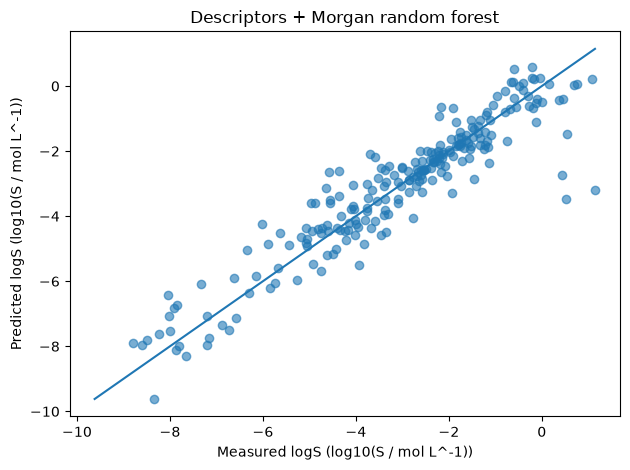

,Feature,Importance
1,logP_rdkit,0.825185
0,MW_rdkit,0.106375
2,TPSA_rdkit,0.048542
4,HBA_rdkit,0.011973
3,HBD_rdkit,0.007925


In [7]:
prediction = predictions[("random_80_20", "RF_combined")]
truth = y_fp[random_test_idx]
limits = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
plt.scatter(truth, prediction, alpha=0.6)
plt.plot(limits, limits)
plt.xlabel("Measured logS (log10(S / mol L^-1))")
plt.ylabel("Predicted logS (log10(S / mol L^-1))")
plt.title("Descriptors + Morgan random forest")
plt.tight_layout()
plt.show()
model = trained_models[("random_80_20", "RF_descriptors")]
display(pd.DataFrame({"Feature": features, "Importance": model.feature_importances_})
        .sort_values("Importance", ascending=False))

## 保留的交叉验证

保留打乱的 5 折描述符验证和组合特征的 GroupKFold；删除与打乱版本重复的未打乱 KFold。GroupKFold 沿用无环分子逐行单独分组的既有策略，不能保证无环相似结构的隔离。交叉验证使用全数据，与独立留出测试结果分开保存。

In [8]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

cv_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    cv_model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

print("R2 scores:", cv_scores)
print("Mean R2:", cv_scores.mean())
print("Std R2:", cv_scores.std())

R2 scores: [0.84978718 0.89773849 0.8860682  0.86312536 0.88185512]
Mean R2: 0.8757148679439869
Std R2: 0.017091956587747387


In [9]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold_group(smiles, idx):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return f"INVALID_{idx}"

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )

    # 无环分子的 Murcko scaffold 是空字符串
    if scaffold == "":
        return f"ACYCLIC_{idx}"

    return scaffold
df_rdkit["scaffold_group"] = [
    get_scaffold_group(smiles, idx)
    for idx, smiles in enumerate(df_rdkit["smiles"])
]
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

groups = df_rdkit["scaffold_group"].values

group_kfold = GroupKFold(
    n_splits=5
)

group_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

group_scores = cross_val_score(
    group_model,
    X_combined,
    y_fp,
    groups=groups,
    cv=group_kfold,
    scoring="r2"
)

print("GroupKFold R2 scores:")
print(group_scores)

print("Mean R2:", group_scores.mean())
print("Std R2:", group_scores.std())

GroupKFold R2 scores:
[0.73273278 0.88521465 0.88869242 0.84592936 0.86643596]
Mean R2: 0.8438010352600556
Std R2: 0.0575905399116148


In [10]:
cv_results = pd.DataFrame([
    {"model": "RF_descriptors", "split": "shuffled_kfold_5", "fold": i + 1, "R2": score}
    for i, score in enumerate(cv_scores)
] + [
    {"model": "RF_combined", "split": "modified_groupkfold_5", "fold": i + 1, "R2": score}
    for i, score in enumerate(group_scores)
])
cv_results.to_csv(project_root / "results" / "cross_validation.csv", index=False, float_format="%.10f")
display(cv_results.groupby(["model", "split"])["R2"].agg(["mean", "std"]))

,,mean,std
model,split,,
RF_combined,modified_groupkfold_5,0.843801,0.064388
RF_descriptors,shuffled_kfold_5,0.875715,0.019109
